# Workshop AI UINIC 8.0 · Sesi 2

**Foundations of Computer Vision: CNN to Transfer Learning** — PyTorch + MobileNetV2

Workshop: Sabtu, 7 November 2026 · FST 303 UIN Sunan Kalijaga

| Babak | Isi | Bagian | Waktu |
|---|---|---|---|
| 1 | Setup dan cek runtime T4 | Langkah 0 | ±5′ |
| 2 | Dataset: impor ZIP, distribusi kelas, sampel | Langkah 1–2 | ±15′ |
| 3 | Model dan training: MobileNetV2 + E1/E2 | Langkah 3–5 | ±30′ |
| 4 | Evaluasi, inferensi, webcam live | Langkah 6–7b | ±20′ |

Dataset contoh: [Potato Disease Data — PlantVillage](https://www.kaggle.com/datasets/aarishasifkhan/plantvillage-potato-disease-dataset) (2152 gambar, 3 kelas, Apache 2.0).

Runtime: **T4 GPU** — Runtime → Change runtime type → T4 GPU.

## Langkah 0 · Setup

Memuat library, mengunci seed, dan memastikan perangkat adalah **T4 GPU**.

- **Seed**: angka awal generator acak. Dengan seed yang sama, hasil bisa diulang.
- **Device**: tempat komputasi. Notebook ini hanya berjalan di GPU (T4 sekitar 10× lebih cepat dari CPU).
- `cek()` mencetak ✅/❌ untuk status tanpa menghentikan notebook.

**Langkah:** Runtime → Change runtime type → **T4 GPU** → Save → jalankan sel di bawah.

In [ ]:
# LANGKAH 0 · Setup — library, seed, device T4
# Jalankan tanpa diubah.
import os, random, shutil, warnings, zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=UserWarning)

# Seed tetap: hasil bisa diulang siapa pun
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# Wajib GPU T4
if not torch.cuda.is_available():
    raise RuntimeError("GPU tidak terdeteksi. Runtime > Change runtime type > "
                       "Hardware accelerator = T4 GPU > Save, lalu jalankan ulang.")
device = torch.device("cuda")
nama_gpu = torch.cuda.get_device_name(0)
if "T4" not in nama_gpu:
    print(f"[catatan] GPU aktif: {nama_gpu}")

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
AKAR = Path("/content") if os.path.isdir("/content") else Path(".")
CKPT = AKAR / "model_terbaik.pt"

def cek(kondisi, teks):
    """Cek misi: cetak status tanpa menghentikan notebook."""
    print(("✅ " if kondisi else "❌ ") + teks)
    return bool(kondisi)

print("Device :", device, "|", nama_gpu)
print("torch  :", torch.__version__, "| torchvision:", torchvision.__version__)

Device : cuda | Tesla T4
torch  : 2.11.0+cu130 | torchvision: 0.26.0+cu130


## Fundamental CNN (demo slide)

Tiga sel singkat: gambar sebagai matriks angka, Conv2d–ReLU–MaxPool, dan dua blok yang memampatkan input 128×128 menjadi vektor 32.768 fitur. Semua demo sintetis, bukan data peserta.

Matriks 8×8 (nilai piksel 0–255, ilustrasi):
 [[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255   0   0   0]
 [  0   0   0 255   0   0   0   0]
 [  0   0   0 255   0   0   0   0]
 [  0   0   0 255   0   0   0   0]
 [  0   0   0 255   0   0   0   0]
 [  0   0   0 255   0   0   0   0]
 [  0   0   0   0   0   0   0   0]]
Bentuk tensor RGB (PyTorch membaca C×H×W, slide 10): (3, 8, 8)


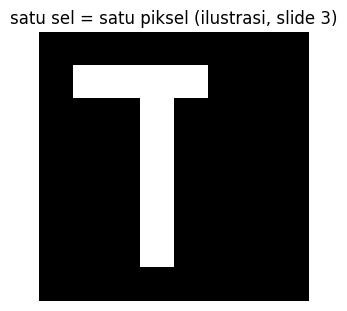

In [ ]:
# FUNDAMENTAL 1 · Gambar = matriks angka — DEMO SINTETIS / ILUSTRASI
papan = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 255, 255, 255, 255, 0, 0, 0],
    [0, 0, 0, 255, 0, 0, 0, 0],
    [0, 0, 0, 255, 0, 0, 0, 0],
    [0, 0, 0, 255, 0, 0, 0, 0],
    [0, 0, 0, 255, 0, 0, 0, 0],
    [0, 0, 0, 255, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
], dtype=np.uint8)
print("Matriks 8×8 (nilai piksel 0–255, ilustrasi):\n", papan)
tensor_citra = torch.from_numpy(np.stack([papan] * 3)).float()   # RGB → 3 kanal
print("Bentuk tensor RGB (PyTorch membaca C×H×W, slide 10):", tuple(tensor_citra.shape))
fig, ax = plt.subplots(figsize=(3, 3), constrained_layout=True)
ax.imshow(papan, cmap="gray"); ax.set_title("satu sel = satu piksel (ilustrasi, slide 3)")
ax.axis("off")
plt.show()


In [ ]:
# FUNDAMENTAL 2 · Conv2d, ReLU, MaxPool — DEMO SINTETIS / ILUSTRASI
x = torch.randn(1, 3, 128, 128)   # satu batch gambar RGB 128×128
print("input            :", tuple(x.shape))

conv = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
y = conv(x)
print("setelah Conv2d   :", tuple(y.shape), "(jumlah filter = 16 → 16 peta fitur)")

demo_relu = torch.tensor([[-2.0, 0.0, 3.0, -1.0]])
print("ReLU f(x)=max(0,x):", demo_relu.tolist(), "→", torch.relu(demo_relu).tolist())

demo_pool = torch.tensor([[1., 3., 5., 8.],
                          [2., 0., 1., 2.],
                          [4., 6., 2., 0.],
                          [9., 7., 3., 1.]])
hasil_pool = nn.MaxPool2d(kernel_size=2)(demo_pool.unsqueeze(0)).squeeze(0)
print("MaxPool2d(2)     :", demo_pool.tolist(), "→", hasil_pool.tolist())

y2 = nn.MaxPool2d(kernel_size=2)(torch.relu(y))
print("setelah ReLU + MaxPool2d(2):", tuple(y2.shape))


input            : (1, 3, 128, 128)
setelah Conv2d   : (1, 16, 128, 128) (jumlah filter = 16 → 16 peta fitur)
ReLU f(x)=max(0,x): [[-2.0, 0.0, 3.0, -1.0]] → [[0.0, 0.0, 3.0, 0.0]]
MaxPool2d(2)     : [[1.0, 3.0, 5.0, 8.0], [2.0, 0.0, 1.0, 2.0], [4.0, 6.0, 2.0, 0.0], [9.0, 7.0, 3.0, 1.0]] → [[3.0, 8.0], [9.0, 3.0]]
setelah ReLU + MaxPool2d(2): (1, 16, 64, 64)


In [ ]:
# FUNDAMENTAL 3 · Dua blok hidden layer — bentuk tensor
# (jalankan setelah sel sebelumnya; x = batch [1, 3, 128, 128])
fitur = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),   # → [16,128,128]
    nn.ReLU(),                                    # negatif → 0
    nn.MaxPool2d(kernel_size=2),                  # → [16,64,64]
    nn.Conv2d(16, 32, kernel_size=3, padding=1),  # → [32,64,64]
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),                  # → [32,32,32]
    nn.Flatten(),                                 # → 32768
)
z = fitur(x)
print("bentuk keluaran flatten:", tuple(z.shape), "→", 32 * 32 * 32, "= 32·32·32 fitur")
print("Di baseline CNN, vektor ini lanjut ke classifier fully connected → N logits.")


bentuk keluaran flatten: (1, 32768) → 32768 = 32·32·32 fitur
Di baseline CNN, vektor ini lanjut ke classifier fully connected → N logits.


## Langkah 1 · Import Dataset

ZIP dataset diambil dari Google Drive, diekstrak, strukturnya dikenali, lalu dibagi train/val/test.

**Struktur ZIP yang dikenali:**
1. folder per kelas di root → dibagi 70/15/15 secara stratified;
2. `train/` + `val/` + `test/` → dipakai apa adanya;
3. `train/` + `test/` → validation diambil 15% dari train.

Struktur lain ditolak dengan pesan jelas.

- **train** = data latihan, **validation** = pemilih setelan, **test** = ujian akhir yang dibuka sekali.
- **Stratified** = proporsi kelas dijaga sama di setiap split.
- Gambar rusak dilewati dan dihitung; folder sistem (`__MACOSX`) diabaikan.
- Setiap kelas minimal 6 gambar agar split 70/15/15 bisa berjalan.


In [ ]:
# Hubungkan Google Drive — lokasi ZIP dataset.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ModuleNotFoundError:
    print("Bukan Colab — arahkan ZIP_PATH ke file ZIP di komputer ini.")

Mounted at /content/drive


In [ ]:
# LANGKAH 1 · Membaca ZIP
# Mengenali 3 struktur ZIP: (1) folder per kelas, (2) train/val/test,
# (3) train + test. Struktur lain DITOLAK dengan pesan jelas (tidak menebak).
# Gambar rusak dilewati & dihitung; folder/file sistem diabaikan.

def _abaikan(name):
    """Lewati folder/file sistem: __MACOSX, file tersembunyi, thumbnail Mac."""
    return name.startswith(".") or name == "__MACOSX" or name.startswith("._")

def ekstrak_zip(zip_path, dest):
    zip_path, dest = Path(zip_path), Path(dest)
    if not zip_path.exists():
        raise FileNotFoundError(f"ZIP tidak ditemukan: {zip_path}\n"
                                "→ Periksa ZIP_PATH. Pastikan ZIP sudah diunggah ke Google Drive.")
    if not zipfile.is_zipfile(zip_path):
        raise ValueError(f"Bukan ZIP yang valid / ZIP rusak: {zip_path}\n"
                         "→ Unduh ulang dataset dari Kaggle, lalu unggah ulang.")
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        for info in z.infolist():
            if any(_abaikan(part) for part in Path(info.filename).parts):
                continue
            target = dest / info.filename
            if info.is_dir():
                target.mkdir(parents=True, exist_ok=True)
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(info) as src, open(target, "wb") as out:
                    shutil.copyfileobj(src, out)
    return dest

def deteksi_dan_siapkan_dataset(zip_path, workdir):
    """Kenali 3 struktur ZIP dan siapkan folder train/val/test.
    Test tidak disentuh sampai Langkah 6."""
    workdir = Path(workdir)
    if workdir.exists():
        shutil.rmtree(workdir)
    sumber = ekstrak_zip(zip_path, workdir / "asal")

    # Buka folder "bungkus" (mis. PlantVillage/<kelas>) — turun satu tingkat.
    top_dir = [d for d in sumber.iterdir() if d.is_dir() and not _abaikan(d.name)]
    top_file = [f for f in sumber.iterdir() if f.is_file()]
    if len(top_dir) == 1 and not top_file and any(
            d.is_dir() and not _abaikan(d.name) for d in top_dir[0].iterdir()):
        sumber = top_dir[0]
        print(f"[info] Dataset di dalam folder bungkus '{sumber.name}' — lanjut ke dalamnya.")

    karantina = workdir / "dilewati_rusak"
    karantina.mkdir(parents=True, exist_ok=True)

    def pindai(folder, rekursif):
        """Kembalikan (gambar valid, jumlah rusak); gambar rusak pindah ke karantina."""
        it = Path(folder).rglob("*") if rekursif else Path(folder).iterdir()
        valid, rusak = [], []
        for p in sorted(it):
            if not p.is_file() or p.suffix.lower() not in IMG_EXTS or any(_abaikan(x) for x in p.parts):
                continue
            try:
                with Image.open(p) as im:
                    im.convert("RGB")          # dekode paksa — gambar rusak gagal di sini
                valid.append(p)
            except Exception:
                rusak.append(p)
        for p in rusak:
            shutil.move(str(p), karantina / p.name)
        return valid, len(rusak)

    def salin(daftar, split_dir):
        for p in daftar:
            dst = split_dir / p.parent.name
            dst.mkdir(parents=True, exist_ok=True)
            shutil.copy2(p, dst / p.name)

    # Deteksi struktur: folder split (train/val/test) atau folder per kelas.
    nama_split = {"train", "training", "val", "validation", "valid", "test", "testing"}
    sub = [d for d in sumber.iterdir() if d.is_dir() and not _abaikan(d.name)]
    sub_map = {d.name.lower(): d for d in sub}
    ada_split = {n for n in sub_map if n in nama_split}
    sub_bergambar = [d for d in sub if any(p.is_file() and p.suffix.lower() in IMG_EXTS
                                           for p in d.iterdir())]   # folder kelas = berisi gambar langsung

    if {"train", "val", "test"}.issubset(ada_split):
        mode = "train_val_test"
    elif {"train", "test"}.issubset(ada_split):
        mode = "train_test"
    elif sub and len(sub_bergambar) == len(sub) and not ada_split:
        mode = "per_kelas"
    else:
        isi = ", ".join(sorted(d.name for d in sub)) or "(tidak ada folder kelas)"
        raise ValueError("Struktur dataset TIDAK dikenali. Folder di root ZIP: " + isi +
                         "\nStruktur yang didukung hanya: (1) folder per kelas di root, "
                         "(2) train/val/test, (3) train + test."
                         "\n→ Susun ulang ZIP dataset sesuai salah satu struktur di atas, lalu unggah ulang.")
    print(f"[info] Struktur terdeteksi: {mode}")

    siap = workdir / "siap"
    total_rusak = 0

    if mode == "per_kelas":
        daftar, label = [], []
        for d in sorted(sub_bergambar, key=lambda x: x.name.lower()):
            v, r = pindai(d, rekursif=False)      # folder kelas: gambar langsung di dalamnya
            total_rusak += r
            daftar.extend(v); label.extend([d.name] * len(v))
        if not daftar:
            raise ValueError("Tidak ada gambar valid di dalam ZIP — data kosong.")
        per_kelas = Counter(label)
        if len(per_kelas) < 2:
            raise ValueError(f"Hanya terdeteksi {len(per_kelas)} kelas ({list(per_kelas)}). "
                             "Klasifikasi butuh minimal 2 kelas.")
        if min(per_kelas.values()) < 6:
            raise ValueError(f"Kelas dengan data terlalu sedikit: {dict(per_kelas)}\n"
                             "→ Minimal 6 gambar per kelas agar split 70/15/15 bisa berjalan.")
        # Split stratified 70/15/15 dengan seed tetap — proporsi kelas terjaga.
        idx_train, idx_temp = train_test_split(
            np.arange(len(daftar)), test_size=0.30, stratify=label, random_state=SEED)
        label_temp = [label[i] for i in idx_temp]
        idx_val, idx_test = train_test_split(
            idx_temp, test_size=0.50, stratify=label_temp, random_state=SEED)
        salin([daftar[i] for i in idx_train], siap / "train")
        salin([daftar[i] for i in idx_val], siap / "val")
        salin([daftar[i] for i in idx_test], siap / "test")

    else:   # mode train_val_test atau train_test
        v_tr, r_tr = pindai(sub_map["train"], rekursif=True); total_rusak += r_tr
        if not v_tr:
            raise ValueError("Folder train tidak berisi gambar valid.")
        if len({p.parent.name for p in v_tr}) < 2:
            raise ValueError("Folder train hanya berisi 1 kelas. Klasifikasi butuh minimal 2 kelas.")
        salin(v_tr, siap / "train")
        if mode == "train_val_test":
            v_va, r_va = pindai(sub_map["val"], rekursif=True); total_rusak += r_va
            if not v_va:
                raise ValueError("Folder val tidak berisi gambar valid.")
            salin(v_va, siap / "val")
        else:   # train + test saja → validation 15% diambil dari train (stratified)
            idx_tr, idx_va = train_test_split(
                np.arange(len(v_tr)), test_size=0.15,
                stratify=[p.parent.name for p in v_tr], random_state=SEED)
            salin([v_tr[i] for i in idx_tr], siap / "train")
            salin([v_tr[i] for i in idx_va], siap / "val")
        v_te, r_te = pindai(sub_map["test"], rekursif=True); total_rusak += r_te
        salin(v_te, siap / "test")

    # Validasi akhir: kelas antar-split harus sama persis.
    kelas = lambda d: sorted(x.name for x in d.iterdir() if x.is_dir())
    k_tr, k_va, k_te = kelas(siap / "train"), kelas(siap / "val"), kelas(siap / "test")
    if set(k_va) != set(k_tr) or set(k_te) != set(k_tr):
        raise ValueError(f"Label split TIDAK cocok!\n  train={k_tr}\n  val={k_va}\n  test={k_te}\n"
                         "→ Pastikan ketiga split memuat kelas yang sama persis (nama folder identik).")

    class_names = k_tr
    jumlah = {s: dict(Counter(p.parent.name for p in (siap / s).rglob("*")
                              if p.suffix.lower() in IMG_EXTS)) for s in ["train", "val", "test"]}
    print(f"[info] Gambar rusak dilewati & dihitung: {total_rusak}")
    return {"mode": mode, "dir": siap, "class_names": class_names,
            "jumlah": jumlah, "n_rusak": total_rusak}


In [ ]:
# Arahkan ZIP_PATH ke ZIP dataset
ZIP_PATH  = Path("/content/Potato Disease Data_PlantVillage.zip")   # ← SESUAIKAN PATH INI
DIR_KERJA = Path("/content/kerja_dataset") if os.path.isdir("/content") else Path("kerja_dataset")

if not ZIP_PATH.exists():
    try:
        from google.colab import files
        print("ZIP tidak ada di ZIP_PATH — pilih file ZIP dari komputer.")
        ZIP_PATH = Path(next(iter(files.upload())))
    except ModuleNotFoundError:
        raise FileNotFoundError(
            f"ZIP tidak ditemukan: {ZIP_PATH}\n→ Perbaiki ZIP_PATH lalu jalankan ulang sel ini.")

INFO = deteksi_dan_siapkan_dataset(ZIP_PATH, DIR_KERJA)
class_names = INFO["class_names"]          # urut abjad = urutan label 0,1,2,...
train_dir, val_dir, test_dir = (INFO["dir"] / s for s in ("train", "val", "test"))
print("Kelas:", class_names)

[info] Dataset di dalam folder bungkus 'PlantVillage' — lanjut ke dalamnya.
[info] Struktur terdeteksi: per_kelas
[info] Gambar rusak dilewati & dihitung: 0
Kelas: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


## Langkah 2 · Inspeksi data

Menampilkan distribusi gambar per kelas (tabel dan grafik) serta contoh foto tiap kelas.

- Dataset **timpang** membuat model berpihak ke kelas mayoritas (bias data), karena itu penilaian memakai **macro-F1**, bukan akurasi saja.
- **Contoh foto** menunjukkan kualitas data: pencahayaan, latar, sudut pengambilan.

**Demo:** sel isian Misi 2 di bawah sudah terisi — tunjukkan inilah yang dikerjakan peserta.

=== INSPEKSI FOLDER ASAL (RAW DATASET) ===
   Potato___Early_blight     : 1000 gambar
   Potato___Late_blight      : 1000 gambar
   Potato___healthy          : 152 gambar
  Total gambar di folder asal: 2152

=== DISTRIBUSI SETELAH SPLIT ===
                       train  val  test
Potato___Early_blight    700  150   150
Potato___Late_blight     700  150   150
Potato___healthy         106   23    23

Total gambar setelah split: 2152 | rusak dilewati: 0


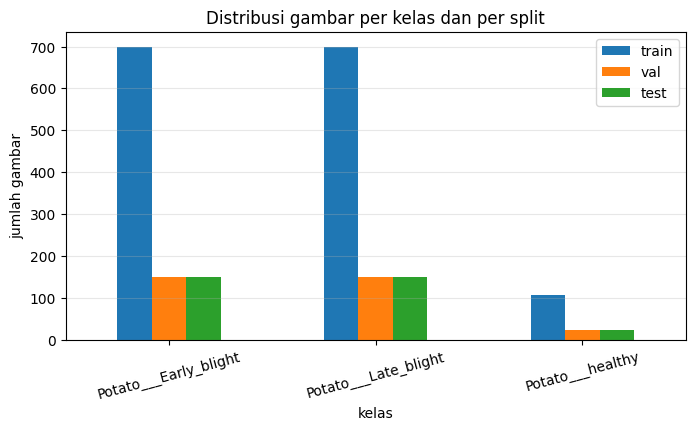

In [ ]:
# LANGKAH 2a · Distribusi gambar per kelas dan per split

# 1. Inspeksi folder asal sebelum split
path_asal = DIR_KERJA / "asal"
# Jika di dalam folder asal ada folder pembungkus (seperti 'PlantVillage')
sub_dir_asal = [d for d in path_asal.iterdir() if d.is_dir() and not d.name.startswith(".") and d.name != "__MACOSX"]
if len(sub_dir_asal) == 1 and any(x.is_dir() for x in sub_dir_asal[0].iterdir()):
    folder_sumber = sub_dir_asal[0]
else:
    folder_sumber = path_asal

print("=== INSPEKSI FOLDER ASAL (RAW DATASET) ===")
if folder_sumber.exists():
    total_raw = 0
    for kelas in sorted(class_names):
        dir_kelas = folder_sumber / kelas
        if dir_kelas.exists():
            n_gambar = len([f for f in dir_kelas.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXTS])
            total_raw += n_gambar
            print(f"   {kelas:<25} : {n_gambar} gambar")
    print(f"  Total gambar di folder asal: {total_raw}\n")
else:
    print("  [Peringatan] Folder asal tidak ditemukan.\n")

# 2. Distribusi setelah dibagi ke train/val/test split
print("=== DISTRIBUSI SETELAH SPLIT ===")
tabel_jumlah = pd.DataFrame(INFO["jumlah"]).reindex(class_names)
print(tabel_jumlah)
print("\nTotal gambar setelah split:", int(tabel_jumlah.values.sum()), "| rusak dilewati:", INFO["n_rusak"])

ax = tabel_jumlah.plot(kind="bar", figsize=(8, 4), rot=15)
ax.set(title="Distribusi gambar per kelas dan per split", xlabel="kelas", ylabel="jumlah gambar")
ax.grid(axis="y", alpha=0.3)
plt.show()

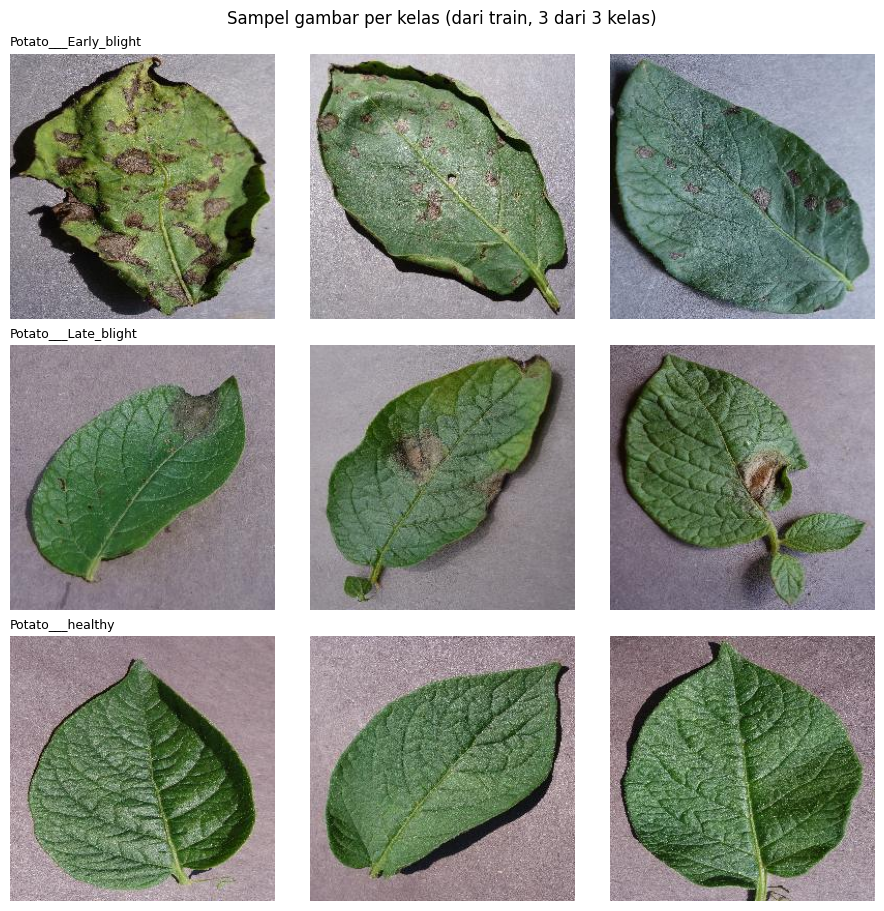

In [ ]:
# LANGKAH 2b · Contoh gambar tiap kelas
n_tampil = 3
kelas_tampil = class_names[:8]
fig, axes = plt.subplots(len(kelas_tampil), n_tampil, constrained_layout=True,
                         figsize=(3 * n_tampil, 3 * len(kelas_tampil)), squeeze=False)
for i, k in enumerate(kelas_tampil):
    sampel = sorted((INFO["dir"] / "train" / k).glob("*"))[:n_tampil]
    for j in range(n_tampil):
        ax = axes[i][j]
        ax.axis("off")
        if j < len(sampel):
            ax.imshow(Image.open(sampel[j]).convert("RGB"))
            if j == 0:
                ax.set_title(k, loc="left", fontsize=9)
plt.suptitle(f"Sampel gambar per kelas (dari train, {len(kelas_tampil)} dari {len(class_names)} kelas)")
plt.show()

In [ ]:
# Memeriksi Jumlah Kelas dan Kelas yang Tersedikit
JUMLAH_KELAS = len(class_names)
KELAS_TERSEDIKIT = min(INFO["jumlah"]["train"], key=INFO["jumlah"]["train"].get)
print("Jumlah kelas:", JUMLAH_KELAS)
print("Kelas tersedikit (train):", KELAS_TERSEDIKIT)

Jumlah kelas: 3
Kelas tersedikit (train): Potato___healthy


## Langkah 3 · Preprocessing & Augmentation

Menyiapkan aturan olah foto sebelum masuk model.

Pipeline wajib semua split: `Resize` (samakan ukuran) → `ToTensor` (piksel 0–255 → 0–1) → `Normalize` (mean/std ImageNet).

- **Mean/std ImageNet**: skala warna saat bobot pretrained dilatih. Data harus disajikan dengan skala yang sama.
- **Augmentasi**: variasi foto latihan tanpa mengumpulkan foto baru (flip, rotasi, color jitter, zoom-crop).
- Augmentasi **hanya di train**; val/test/inference deterministik agar evaluasi bisa diulang. Rotasi besar bisa mengubah makna label (6 ↔ 9).


In [ ]:
# flip = cermin, rotasi = dimiringkan, kecerahan/kontras = variasi cahaya, zoom = crop acak.
PANEL_AUGMENTASI = {
    "aktif":           True,   # efek hanya di train
    "flip_horizontal": 0.5,    # 0.0-1.0
    "flip_vertical":   0.0,    # 0.0-1.0 — objek terbalik jarang alami
    "rotasi_derajat":  15,     # 0-30 — rotasi besar bisa mengubah makna label
    "kecerahan":       0.2,    # 0.0-0.5
    "kontras":         0.2,    # 0.0-0.5
    "zoom_min_skala":  0.8,    # 0.5-1.0 (1.0 = tanpa zoom-crop)
    "ukuran_gambar":   128,    # 96 / 128 / 160 / 224
}
print("PANEL_AUGMENTASI saat ini:", PANEL_AUGMENTASI)

PANEL_AUGMENTASI saat ini: {'aktif': True, 'flip_horizontal': 0.5, 'flip_vertical': 0.0, 'rotasi_derajat': 15, 'kecerahan': 0.2, 'kontras': 0.2, 'zoom_min_skala': 0.8, 'ukuran_gambar': 128}


In [ ]:
# Aturan: augmentasi acak hanya di train; val/test/inference deterministik.
# Pipeline semua split: Resize -> ToTensor -> Normalize(ImageNet).
def periksa_panel_augmentasi(p):
    """Tolak nilai di luar rentang dengan pesan jelas."""
    batas = {"flip_horizontal": (0, 1), "flip_vertical": (0, 1),
             "rotasi_derajat": (0, 30), "kecerahan": (0, 0.5),
             "kontras": (0, 0.5), "zoom_min_skala": (0.5, 1.0)}
    salah = []
    for k, (lo, hi) in batas.items():
        v = p.get(k)
        if not (isinstance(v, (int, float)) and lo <= v <= hi):
            salah.append(f"{k}={v} (harus {lo}-{hi})")
    if not isinstance(p.get("aktif"), bool):
        salah.append(f"aktif={p.get('aktif')} (harus True/False)")
    if p.get("ukuran_gambar") not in (96, 128, 160, 224):
        salah.append(f"ukuran_gambar={p.get('ukuran_gambar')} (pilih 96/128/160/224)")
    if salah:
        raise ValueError("PANEL_AUGMENTASI tidak valid:\n  " + "\n  ".join(salah))
    if p["flip_vertical"] > 0:
        print("[catatan] flip_vertical > 0 — pastikan masuk akal untuk datasetmu.")
    print("✅ PANEL_AUGMENTASI valid.")

def ops_augmentasi(p):
    """Daftar augmentasi acak (belum termasuk ToTensor/Normalize)."""
    u = p["ukuran_gambar"]
    if p["zoom_min_skala"] < 1.0:
        ops = [transforms.RandomResizedCrop(u, scale=(p["zoom_min_skala"], 1.0))]
    else:
        ops = [transforms.Resize((u, u))]
    if p["flip_horizontal"] > 0:
        ops.append(transforms.RandomHorizontalFlip(p=p["flip_horizontal"]))
    if p["flip_vertical"] > 0:
        ops.append(transforms.RandomVerticalFlip(p=p["flip_vertical"]))
    if p["rotasi_derajat"] > 0:
        ops.append(transforms.RandomRotation(p["rotasi_derajat"]))
    if p["kecerahan"] > 0 or p["kontras"] > 0:
        ops.append(transforms.ColorJitter(brightness=p["kecerahan"], contrast=p["kontras"]))
    return ops

def bangun_transform_train(p):
    """Train: augmentasi acak (bila aktif) + ToTensor + Normalize."""
    if not p["aktif"]:
        return bangun_transform_eval(p)
    return transforms.Compose(ops_augmentasi(p)
                              + [transforms.ToTensor(),
                                 transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])

def bangun_transform_eval(p):
    """Val/test/inference: deterministik."""
    u = p["ukuran_gambar"]
    return transforms.Compose([
        transforms.Resize((u, u)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

✅ PANEL_AUGMENTASI valid.
Jumlah gambar -> train: 1506 | val: 323 | test: 323
✅ RUMPANG-1 urutan transform eval: ['Resize', 'ToTensor', 'Normalize'] (harus Resize → ToTensor → Normalize).


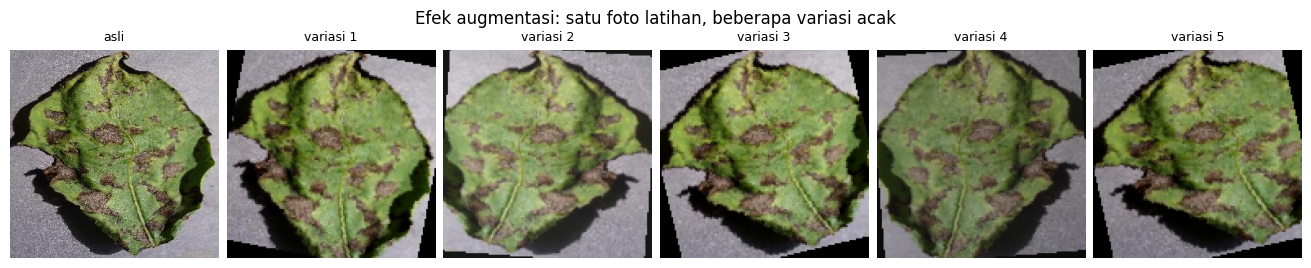

In [ ]:
# Terapkan panel -> transform -> dataset, lalu pratinjau augmentasi.
periksa_panel_augmentasi(PANEL_AUGMENTASI)
tf_train = bangun_transform_train(PANEL_AUGMENTASI)
tf_eval = bangun_transform_eval(PANEL_AUGMENTASI)

train_ds = datasets.ImageFolder(str(train_dir), transform=tf_train)
val_ds = datasets.ImageFolder(str(val_dir), transform=tf_eval)
test_ds = datasets.ImageFolder(str(test_dir), transform=tf_eval)
assert train_ds.classes == class_names, "Urutan kelas beda dengan INFO — periksa struktur ZIP."
print("Jumlah gambar -> train:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))

jenis = [type(t).__name__ for t in tf_eval.transforms]
cek(jenis == ["Resize", "ToTensor", "Normalize"],
    f"RUMPANG-1 urutan transform eval: {jenis} (harus Resize → ToTensor → Normalize).")

# Pratinjau: satu foto latihan, lima variasi acak
foto_asli = Image.open(train_ds.samples[0][0]).convert("RGB")
acak = transforms.Compose(ops_augmentasi(PANEL_AUGMENTASI))
gambar = [foto_asli] + [acak(foto_asli) for _ in range(5)]
judul = ["asli"] + [f"variasi {i}" for i in range(1, 6)]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6), constrained_layout=True, squeeze=False)
for ax, g, t in zip(axes[0], gambar, judul):
    ax.imshow(g); ax.set_title(t, fontsize=9); ax.axis("off")
plt.suptitle("Efek augmentasi: satu foto latihan, beberapa variasi acak")
plt.show()

## Langkah 4 · Model — Transfer Learning MobileNetV2

Membangun model dari bobot pretrained, bukan dari nol.

- **Transfer learning**: model yang sudah dilatih di ImageNet dipakai sebagai titik awal; fitur umum (tepi, tekstur, bentuk) dipakai ulang.
- **Backbone dibekukan** (`requires_grad=False`): bobotnya tidak diubah. Hanya **head** baru `Linear(1280 → N)` yang dilatih (3 kelas = 3.843 parameter).
- **Logits**: satu skor per kelas tanpa softmax. `CrossEntropyLoss` menangani softmax saat training; softmax dipakai saat inference.
- Backbone tetap `eval()` saat training agar statistik **BatchNorm** tidak bergeser.


In [ ]:
# Tiap percobaan memanggil bangun_model() lagi, selalu dari bobot pretrained baru.
def bangun_model():
    num_kelas = len(class_names)
    backbone = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    for p in backbone.features.parameters():
        p.requires_grad = False
    backbone.classifier[1] = nn.Linear(1280, num_kelas)
    return backbone.to(device)

model = bangun_model()
_beku = all(not p.requires_grad for p in model.features.parameters())
_hidup = all(p.requires_grad for p in model.classifier[1].parameters())
_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
cek(_beku, "seluruh backbone.features beku (requires_grad=False).")
cek(_hidup, "head classifier[1] trainable — hanya head yang dilatih.")
cek(_train == 1280 * len(class_names) + len(class_names),
    f"Parameter trainable = {_train:,} = 1280×{len(class_names)} + {len(class_names)}.")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 121MB/s]


✅ seluruh backbone.features beku (requires_grad=False).
✅ head classifier[1] trainable — hanya head yang dilatih.
✅ Parameter trainable = 3,843 = 1280×3 + 3.


True

## Langkah 5 · Training & eksperimen hyperparameter

Melatih head pada data train, menilai di validation setiap epoch, dan mencatat tiap percobaan di tabel `RUNS`.

| Istilah | Arti singkat |
|---|---|
| **epoch** | satu putaran penuh seluruh data train |
| **batch size** | banyak foto diproses sekaligus |
| **learning rate** | ukuran langkah pembaruan bobot — terlalu besar: loss melompat; terlalu kecil: lambat |
| **optimizer** | algoritme pembaruan bobot (Adam / SGD) |
| **overfitting** | train loss turun, val loss naik — model menghafal |

Aturan: ubah **satu variabel** per percobaan. Model terbaik dipilih dari **validation macro-F1**; test tidak disentuh di tahap ini.

**Panduan E2:**
1. jalankan **E1** dengan nilai panel apa adanya;
2. untuk **E2** ubah **satu** nilai — rekomendasinya **`learning_rate` saja** (1e-3 → 1e-4 bila loss melompat atau naik-turun, 1e-2 bila terlalu lambat);
3. jalankan sel **E2**, lalu bandingkan val macro-F1 di tabel `RUNS`;
4. tulis hasil perbandingan di `CATATAN["analisis_tuning"]`; sebab-akibat satu variabel jadi jelas.

**Epoch** bebas (minimal 1). Panduan kelipatan 8: **8** cepat, **16** seimbang, **32** lama dan rawan overfitting. Nilai lain tetap boleh, hanya muncul saran.

In [ ]:
# Panel hyperparameter.
# epochs        : bebas (>=1). Panduan kelipatan 8 — 8 cepat / 16 seimbang / 32 lama + rawan overfitting.
# batch_size    : 8-64 (32 aman untuk T4).
# learning_rate : 1e-5 sampai 1e-2 (1e-3 titik awal umum untuk Adam).
# optimizer     : "adam" (umum) atau "sgd" (pembanding).
PANEL_HYPER = {
    "epochs":        16,
    "batch_size":    32,
    "learning_rate": 1e-3,   # loss melompat / NaN -> turunkan 10x
    "optimizer":     "adam",
}
print("PANEL_HYPER saat ini:", PANEL_HYPER)

PANEL_HYPER saat ini: {'epochs': 16, 'batch_size': 32, 'learning_rate': 0.001, 'optimizer': 'adam'}


In [ ]:
# Mesin training
# Tiap percobaan memakai model baru dari bobot pretrained, backbone beku tetap eval(),
# model terbaik dipilih dari validation macro-F1. Test tidak disentuh di sini.
CRITERION = nn.CrossEntropyLoss()
RUNS, TERBAIK_F1 = [], -1.0
REKOMENDASI_EPOCH = (8, 16, 32)

def ringkas_augmentasi():
    """Teks ringkas setelan augmentasi untuk tabel percobaan."""
    p = PANEL_AUGMENTASI
    if not p["aktif"]:
        return f"{p['ukuran_gambar']}px; tanpa augmentasi"
    isi = [f"{k}={v}" for k, v in p.items() if k not in ("aktif", "ukuran_gambar") and v]
    return f"{p['ukuran_gambar']}px; " + (", ".join(isi) or "-")

def periksa_panel_hyper(p):
    """Tolak nilai yang tidak masuk akal; nilai di luar panduan hanya diberi saran."""
    salah, saran = [], []
    ep = p.get("epochs")
    if not (isinstance(ep, int) and not isinstance(ep, bool) and ep >= 1):
        salah.append(f"epochs={ep} harus bilangan bulat >= 1")
    elif ep not in REKOMENDASI_EPOCH:
        saran.append(f"[saran] epochs={ep}: panduan workshop 8 (cepat), 16 (seimbang), 32 (lama).")
    bs = p.get("batch_size")
    if not (isinstance(bs, int) and not isinstance(bs, bool) and bs >= 1):
        salah.append(f"batch_size={bs} harus bilangan bulat >= 1")
    elif bs > 64:
        saran.append(f"[saran] batch_size={bs} besar untuk T4; mulai dari 32 bila memori penuh.")
    lr = p.get("learning_rate")
    if not (isinstance(lr, (int, float)) and lr > 0):
        salah.append(f"learning_rate={lr} harus angka > 0")
    elif not 1e-5 <= lr <= 1e-2:
        saran.append(f"[saran] learning_rate={lr} di luar rentang lazim 1e-5 sampai 1e-2.")
    if p.get("optimizer") not in ("adam", "sgd"):
        salah.append('optimizer harus "adam" atau "sgd"')
    if salah:
        raise ValueError("PANEL_HYPER tidak valid:\n  " + "\n  ".join(salah))
    for s in saran:
        print(s)
    print("✅ PANEL_HYPER valid.")

def bangun_optimizer(p, model):
    """Optimizer hanya untuk parameter trainable (hanya head)."""
    trainable = [q for q in model.parameters() if q.requires_grad]
    if p["optimizer"] == "adam":
        return optim.Adam(trainable, lr=p["learning_rate"])
    return optim.SGD(trainable, lr=p["learning_rate"], momentum=0.9)

def latih_satu_epoch(model, loader, optimizer=None):
    """Satu putaran data; optimizer=None berarti mode evaluasi."""
    latih = optimizer is not None
    model.train(latih)
    if latih:
        model.features.eval()          # BatchNorm backbone tetap eval
    total, benar, n = 0.0, 0, 0
    y_true, y_pred = [], []
    konteks = torch.enable_grad() if latih else torch.inference_mode()
    with konteks:
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(x)
            loss = CRITERION(logits, y)
            if latih:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(y)
            n += len(y)
            pred = logits.argmax(1)
            benar += (pred == y).sum().item()
            y_true += y.tolist()
            y_pred += pred.tolist()
    return total / max(n, 1), benar / max(n, 1), y_true, y_pred

def jalankan_percobaan(tag):
    """Satu percobaan: model baru, latih, pilih epoch terbaik lewat validation."""
    global TERBAIK_F1
    periksa_panel_hyper(PANEL_HYPER)
    epochs = PANEL_HYPER["epochs"]
    cfg = {**PANEL_HYPER, "augmentasi": ringkas_augmentasi()}
    if RUNS:
        beda = [k for k in PANEL_HYPER if PANEL_HYPER[k] != RUNS[-1]["cfg"][k]]
        if len(beda) == 1:
            print(f"[ok] satu variabel berubah: {beda[0]} — eksperimen terkontrol.")
        elif len(beda) > 1:
            print(f"[catatan] {len(beda)} variabel berubah: {beda} — sebaiknya satu per percobaan.")

    ukuran = PANEL_HYPER["batch_size"]
    loader_train = DataLoader(
        datasets.ImageFolder(str(train_dir), transform=bangun_transform_train(PANEL_AUGMENTASI)),
        batch_size=ukuran, shuffle=True, num_workers=2, pin_memory=True)
    loader_val = DataLoader(
        datasets.ImageFolder(str(val_dir), transform=bangun_transform_eval(PANEL_AUGMENTASI)),
        batch_size=ukuran, shuffle=False, num_workers=2, pin_memory=True)

    model = bangun_model()
    optimizer = bangun_optimizer(PANEL_HYPER, model)
    print(f"\n=== {tag} | {epochs} epoch | batch {ukuran} | lr {PANEL_HYPER['learning_rate']} | "
          f"{PANEL_HYPER['optimizer']} | {ringkas_augmentasi()} ===")

    hist_train, hist_val = [], []
    best_f1, best_ep, best_state = -1.0, 0, None
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc, _, _ = latih_satu_epoch(model, loader_train, optimizer)
        va_loss, va_acc, y_v, p_v = latih_satu_epoch(model, loader_val)
        va_f1 = f1_score(y_v, p_v, average="macro", zero_division=0)
        hist_train.append(tr_loss)
        hist_val.append(va_loss)
        tanda = ""
        if va_f1 > best_f1:
            best_f1, best_ep, tanda = va_f1, ep, "  ← terbaik"
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"Epoch {ep:02d}/{epochs} | train loss {tr_loss:.3f} acc {tr_acc:.2f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.2f} | macro-F1 {va_f1:.3f}{tanda}")

    RUNS.append({"tag": tag, "epochs": epochs, "epoch_terbaik": best_ep,
                 "val_f1": round(float(best_f1), 3), "cfg": cfg})
    if best_state is not None and best_f1 > TERBAIK_F1:
        TERBAIK_F1 = best_f1
        torch.save({"state_dict": best_state, "class_names": class_names,
                    "image_size": PANEL_AUGMENTASI["ukuran_gambar"],
                    "mean": IMAGENET_MEAN, "std": IMAGENET_STD,
                    "percobaan": tag, "val_f1": round(float(best_f1), 3)}, CKPT)
        print("→ checkpoint terbaik disimpan:", CKPT)

    fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
    ax.plot(range(1, epochs + 1), hist_train, marker="o", label="train loss")
    ax.plot(range(1, epochs + 1), hist_val, marker="o", label="val loss")
    ax.set(xlabel="epoch", ylabel="loss", title=f"Percobaan {tag}: kurva loss")
    ax.legend(); ax.grid(alpha=0.3)
    plt.show()
    print(pd.DataFrame(RUNS).to_string(index=False))

print("Mesin training siap — jalankan percobaan di sel berikutnya.")

Mesin training siap — jalankan percobaan di sel berikutnya.


✅ PANEL_HYPER valid.

=== E1 | 16 epoch | batch 32 | lr 0.001 | adam | 128px; flip_horizontal=0.5, rotasi_derajat=15, kecerahan=0.2, kontras=0.2, zoom_min_skala=0.8 ===
Epoch 01/16 | train loss 0.411 acc 0.85 | val loss 0.232 acc 0.92 | macro-F1 0.864  ← terbaik
Epoch 02/16 | train loss 0.203 acc 0.94 | val loss 0.174 acc 0.94 | macro-F1 0.897  ← terbaik
Epoch 03/16 | train loss 0.149 acc 0.95 | val loss 0.153 acc 0.96 | macro-F1 0.917  ← terbaik
Epoch 04/16 | train loss 0.133 acc 0.96 | val loss 0.131 acc 0.96 | macro-F1 0.934  ← terbaik
Epoch 05/16 | train loss 0.116 acc 0.96 | val loss 0.118 acc 0.98 | macro-F1 0.969  ← terbaik
Epoch 06/16 | train loss 0.100 acc 0.97 | val loss 0.110 acc 0.97 | macro-F1 0.961
Epoch 07/16 | train loss 0.100 acc 0.97 | val loss 0.110 acc 0.96 | macro-F1 0.939
Epoch 08/16 | train loss 0.090 acc 0.97 | val loss 0.103 acc 0.97 | macro-F1 0.953
Epoch 09/16 | train loss 0.086 acc 0.97 | val loss 0.100 acc 0.97 | macro-F1 0.951
Epoch 10/16 | train loss 0.07

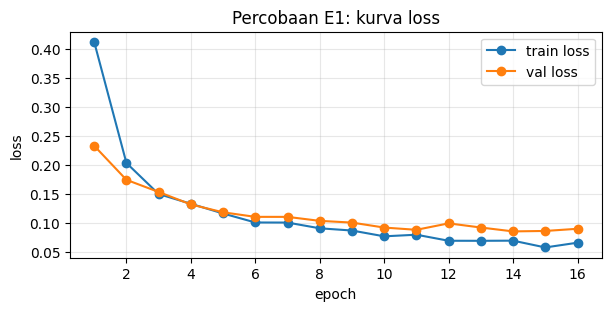

tag  epochs  epoch_terbaik  val_f1                                                                                                                                                                                          cfg
 E1      16              5   0.969 {'epochs': 16, 'batch_size': 32, 'learning_rate': 0.001, 'optimizer': 'adam', 'augmentasi': '128px; flip_horizontal=0.5, rotasi_derajat=15, kecerahan=0.2, kontras=0.2, zoom_min_skala=0.8'}


In [ ]:
# E1 — percobaan pertama: nilai panel apa adanya (lr 1e-3).
jalankan_percobaan("E1")

✅ PANEL_HYPER valid.
[ok] satu variabel berubah: learning_rate — eksperimen terkontrol.

=== E2 | 16 epoch | batch 32 | lr 0.0001 | adam | 128px; flip_horizontal=0.5, rotasi_derajat=15, kecerahan=0.2, kontras=0.2, zoom_min_skala=0.8 ===
Epoch 01/16 | train loss 0.809 acc 0.67 | val loss 0.665 acc 0.81 | macro-F1 0.560  ← terbaik
Epoch 02/16 | train loss 0.591 acc 0.81 | val loss 0.548 acc 0.86 | macro-F1 0.594  ← terbaik
Epoch 03/16 | train loss 0.503 acc 0.84 | val loss 0.473 acc 0.87 | macro-F1 0.605  ← terbaik
Epoch 04/16 | train loss 0.441 acc 0.86 | val loss 0.415 acc 0.88 | macro-F1 0.611  ← terbaik
Epoch 05/16 | train loss 0.391 acc 0.86 | val loss 0.374 acc 0.89 | macro-F1 0.619  ← terbaik
Epoch 06/16 | train loss 0.361 acc 0.88 | val loss 0.342 acc 0.90 | macro-F1 0.624  ← terbaik
Epoch 07/16 | train loss 0.328 acc 0.89 | val loss 0.315 acc 0.90 | macro-F1 0.650  ← terbaik
Epoch 08/16 | train loss 0.296 acc 0.92 | val loss 0.293 acc 0.91 | macro-F1 0.703  ← terbaik
Epoch 09/16

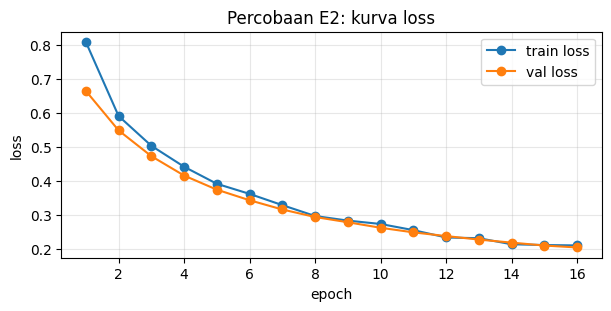

tag  epochs  epoch_terbaik  val_f1                                                                                                                                                                                           cfg
 E1      16              5   0.969  {'epochs': 16, 'batch_size': 32, 'learning_rate': 0.001, 'optimizer': 'adam', 'augmentasi': '128px; flip_horizontal=0.5, rotasi_derajat=15, kecerahan=0.2, kontras=0.2, zoom_min_skala=0.8'}
 E2      16             15   0.866 {'epochs': 16, 'batch_size': 32, 'learning_rate': 0.0001, 'optimizer': 'adam', 'augmentasi': '128px; flip_horizontal=0.5, rotasi_derajat=15, kecerahan=0.2, kontras=0.2, zoom_min_skala=0.8'}
✅ Misi 5: 2 percobaan tercatat.


True

In [ ]:
# E2 — demo "ubah satu variabel": learning_rate 1e-3 → 1e-4.
# Turunkan 10x bila loss melompat atau naik-turun; naikkan 10x bila konvergensi terlalu lambat.
PANEL_HYPER["learning_rate"] = 1e-4
jalankan_percobaan("E2")
cek(len(RUNS) >= 2, f"Misi 5: {len(RUNS)} percobaan tercatat.")

## Langkah 6 · Test final (sekali)

Mengevaluasi checkpoint terbaik di test set — sekali saja, setelah semua keputusan selesai.

- **Akurasi**: porsi prediksi yang benar. **Macro-F1**: rata-rata F1 semua kelas dengan bobot sama.
- **Classification report**: *precision* = dari yang diprediksi X, berapa yang benar; *recall* = dari yang aslinya X, berapa yang tertangkap.
- **Confusion matrix**: diagonal = benar; di luar diagonal = kelas yang sering tertukar.


Checkpoint E1 | val macro-F1 0.969 | ukuran 128px
HASIL TEST (sekali): {'akurasi': 0.969, 'f1_macro': 0.951} 

                       precision    recall  f1-score   support

Potato___Early_blight       0.99      0.97      0.98       150
 Potato___Late_blight       0.94      0.99      0.97       150
     Potato___healthy       1.00      0.83      0.90        23

             accuracy                           0.97       323
            macro avg       0.98      0.93      0.95       323
         weighted avg       0.97      0.97      0.97       323



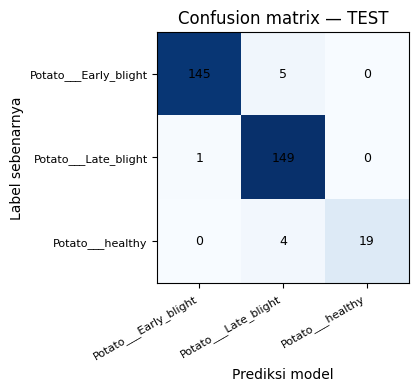

In [ ]:
# LANGKAH 6 · Test final — dijalankan sekali, setelah semua keputusan selesai.
ck = torch.load(CKPT, map_location=device, weights_only=True)
assert ck["class_names"] == class_names, "Kelas checkpoint berbeda dengan dataset — latih ulang dulu."
model = bangun_model()
model.load_state_dict(ck["state_dict"])
model.eval()
print(f"Checkpoint {ck['percobaan']} | val macro-F1 {ck['val_f1']} | ukuran {ck['image_size']}px")

# Transform mengikuti metadata checkpoint (deterministik, sama seperti saat validasi)
tf_test = transforms.Compose([
    transforms.Resize((ck["image_size"], ck["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=ck["mean"], std=ck["std"]),
])
loader_test = DataLoader(datasets.ImageFolder(str(test_dir), transform=tf_test),
                         batch_size=32, shuffle=False, num_workers=2)
_, akurasi, y_true, y_pred = latih_satu_epoch(model, loader_test)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
HASIL_TEST = {"akurasi": round(float(akurasi), 3), "f1_macro": round(float(f1_macro), 3)}
print("HASIL TEST (sekali):", HASIL_TEST, "\n")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
fig, ax = plt.subplots(figsize=(4.5, 3.8), constrained_layout=True)
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names, fontsize=8)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=9)
ax.set(xlabel="Prediksi model", ylabel="Label sebenarnya", title="Confusion matrix — TEST")
plt.show()

## Langkah 7 · Inferensi & ambang keyakinan

Model dipakai sungguhan: foto → label + keyakinan (softmax 0–1).

- **Softmax** mengubah logits menjadi probabilitas yang jumlahnya 1.
- **Ambang keyakinan**: keyakinan ≥ ambang → **YAKIN** (boleh menjadi masukan keputusan); di bawahnya → **RAGU** (foto ulang atau periksa manusia).
- **Batas domain**: model selalu memilih satu kelas, termasuk untuk gambar di luar dataset. Jaringan modern sering *overconfident*, jadi skor tinggi tetap bisa salah.

✅ AMBANG_KONFIDENSI di rentang 0.5-0.95.


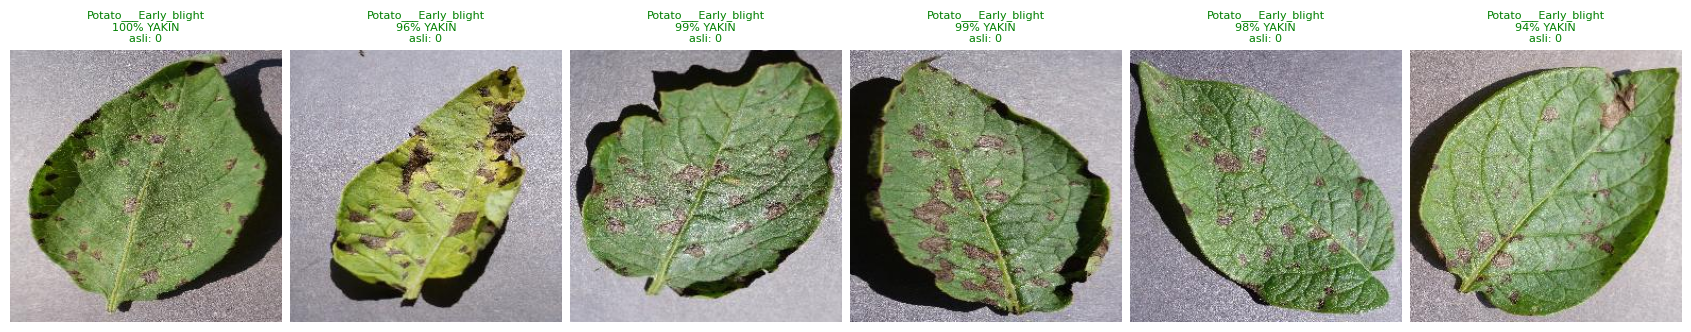

0 dari 6 contoh di bawah ambang — perlu pemeriksaan manusia.


In [ ]:
# LANGKAH 7 · Inferensi: foto -> label + keyakinan (softmax 0-1).
AMBANG_KONFIDENSI = 0.60    # parameter demonstrasi, bukan jaminan akurasi
cek(0.5 <= AMBANG_KONFIDENSI <= 0.95, "AMBANG_KONFIDENSI di rentang 0.5-0.95.")

def prediksi_gambar(gambar):
    """Path file atau objek PIL -> (label, keyakinan 0-1)."""
    img = gambar if isinstance(gambar, Image.Image) else Image.open(gambar)
    with torch.inference_mode():
        proba = torch.softmax(model(tf_test(img.convert("RGB")).unsqueeze(0).to(device)), dim=1)[0]
    k = int(proba.argmax())
    return class_names[k], float(proba[k])

pilih = random.Random(SEED).sample(range(len(test_ds.samples)), min(6, len(test_ds.samples)))
fig, axes = plt.subplots(1, len(pilih), figsize=(2.8 * len(pilih), 3.6),
                         constrained_layout=True, squeeze=False)
n_ragu = 0
for ax, i in zip(axes[0], pilih):
    path, label_asli = test_ds.samples[i]
    label, conf = prediksi_gambar(path)
    yakin = conf >= AMBANG_KONFIDENSI
    n_ragu += (not yakin)
    ax.imshow(Image.open(path).convert("RGB")); ax.axis("off")
    ax.set_title(f"{label}\n{conf*100:.0f}% {'YAKIN' if yakin else 'RAGU'}\nasli: {label_asli}",
                 fontsize=8, color="green" if yakin else "darkorange")
plt.show()
print(f"{n_ragu} dari {len(pilih)} contoh di bawah ambang — perlu pemeriksaan manusia.")

## Langkah 7b · Opsional — Upload gambar sendiri & webcam live

Dua sel untuk menguji model di luar test set; jalankan setelah Langkah 7.

- **Sel A (unggah)**: pilih 1–8 foto dari komputer yang sudah diunduh; isi `LABEL_ASLI` bila ingin akurasi manual dihitung.
- **Sel B (webcam live)**: izinkan kamera, lalu sel memproses frame berulang selama `JUMLAH_FRAME` dan menampilkan label + keyakinan di atas gambar. Tidak perlu klik ulang setiap frame.

Kamera berjalan di browser, jadi yang dipakai adalah webcam laptop. Ingat **batas domain**: gambar di luar kelas dataset tetap diprediksi sebagai salah satu kelas — baca status YAKIN/RAGU secara kritis.

Saving Gambar-Gejala-Bercak-Daun-Alternaria-pada-Kentang.jpg to Gambar-Gejala-Bercak-Daun-Alternaria-pada-Kentang.jpg
Gambar-Gejala-Bercak-Daun-Alternaria-pada-Kentang.jpg -> Potato___Early_blight (79%)


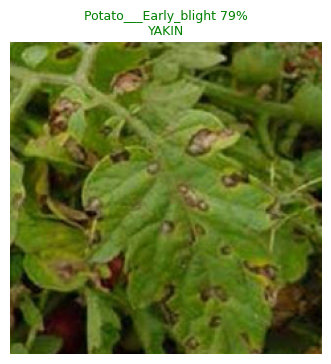

Isi LABEL_ASLI bila ingin menghitung akurasi manual.


In [ ]:
# Uji gambar sendiri: unggah 1-8 foto, lihat prediksi + keyakinan.
try:
    from google.colab import files
except ModuleNotFoundError:
    raise RuntimeError("Sel ini memakai google.colab.files (jalankan di Colab).")

LABEL_ASLI = {}   # opsional: {"nama file.jpg": "nama kelas persis seperti class_names"}

terunggah = files.upload()
daftar = list(terunggah)[:8]
if not daftar:
    print("Tidak ada file yang diunggah.")
else:
    fig, axes = plt.subplots(1, len(daftar), figsize=(3.2 * len(daftar), 3.8),
                             constrained_layout=True, squeeze=False)
    benar, dinilai = 0, 0
    for ax, nama in zip(axes[0], daftar):
        gambar = Image.open(nama).convert("RGB")
        label, conf = prediksi_gambar(gambar)
        yakin = conf >= AMBANG_KONFIDENSI
        ax.imshow(gambar); ax.axis("off")
        ax.set_title(f"{label} {conf*100:.0f}%\n{'YAKIN' if yakin else 'RAGU'}", fontsize=9,
                     color="green" if yakin else "darkorange")
        print(f"{nama} -> {label} ({conf*100:.0f}%)")
        if nama in LABEL_ASLI:
            dinilai += 1
            benar += int(LABEL_ASLI[nama] == label)
    plt.show()
    if dinilai:
        print(f"Akurasi manual: {benar}/{dinilai} gambar berlabel.")
    else:
        print("Isi LABEL_ASLI bila ingin menghitung akurasi manual.")

kamera aktif 640x480 | memproses 40 frame menggunakan model_terbaik.pt... (Ambang: 0.6 )


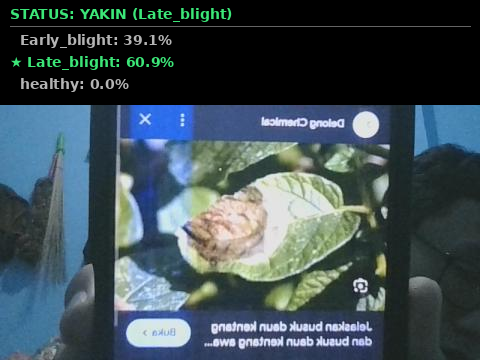

Selesai. Kamera tetap aktif agar sel bisa dijalankan ulang.


In [ ]:
# Deteksi live dari webcam laptop (Colab + Chrome)
# 1) Jalankan sel, klik Allow saat browser meminta izin kamera.
# 2) Frame diprediksi berulang selama JUMLAH_FRAME, lalu sel berhenti sendiri.
# Kamera berjalan di browser, jadi yang dipakai adalah webcam laptop. Ingat **batas domain**: gambar di luar kelas dataset tetap diprediksi sebagai salah satu kelas — baca status YAKIN/RAGU secara kritis.

import base64, io, time
from PIL import ImageDraw, ImageFont
import matplotlib.font_manager as fm
from IPython.display import display
try:
    from google.colab.output import eval_js
except ModuleNotFoundError:
    raise RuntimeError("Sel ini khusus Google Colab. Di laptop biasa, gunakan cv2.VideoCapture.")

assert "prediksi_gambar" in globals(), "Jalankan Langkah 7 dulu (model + prediksi_gambar)."

JUMLAH_FRAME = 40     # sekitar 15 detik; ubah bila perlu
JEDA_FRAME = 0.10     # jeda antar frame (detik)

JS_BUKA = """
(async () => {
  if (window.__cam) return "kamera sudah aktif";
  const video = document.createElement('video');
  video.autoplay = true; video.muted = true; video.playsInline = true;
  video.style.display = 'none';
  document.body.appendChild(video);
  try {
    const stream = await navigator.mediaDevices.getUserMedia({video: {width: 640, height: 480}});
    video.srcObject = stream;
    await video.play();
    await new Promise(r => setTimeout(r, 600));
    window.__cam = {video: video, canvas: document.createElement('canvas'), stream: stream};
    return "kamera aktif " + video.videoWidth + "x" + video.videoHeight;
  } catch (err) {
    throw new Error(err.name + ": " + err.message + "\\n\\nTips: Klik ikon gembok di sebelah kiri URL Chrome -> ubah izin Kamera menjadi 'Allow' secara manual.");
  }
})()
"""

JS_FRAME = """
(() => {
  const c = window.__cam;
  if (!c || !c.video.videoWidth) return "";
  const w = 480, h = Math.round(w * c.video.videoHeight / c.video.videoWidth);
  c.canvas.width = w; c.canvas.height = h;
  const ctx = c.canvas.getContext('2d');
  ctx.save(); ctx.translate(w, 0); ctx.scale(-1, 1);
  ctx.drawImage(c.video, 0, 0, w, h);
  ctx.restore();
  return c.canvas.toDataURL('image/jpeg', 0.75);
})()
"""

try:
    FONT = ImageFont.truetype(fm.findfont("DejaVu Sans:bold"), 14)
except Exception:
    FONT = ImageFont.load_default()

def prediksi_semua_skor(gambar):
    """Mengmengembalikan skor probabilitas untuk semua kelas."""
    img = gambar if isinstance(gambar, Image.Image) else Image.open(gambar)
    with torch.inference_mode():
        proba = torch.softmax(model(tf_test(img.convert("RGB")).unsqueeze(0).to(device)), dim=1)[0]
    return proba.tolist()

def tandai_frame_lengkap(img, probabilitas):
    """Tempel semua label beserta skor probabilitas, serta status keyakinan berdasarkan AMBANG_KONFIDENSI."""
    g = img.copy()
    d = ImageDraw.Draw(g)

    # Membaca ambang konfidensi global
    ambang = globals().get("AMBANG_KONFIDENSI", 0.70)

    # Cari skor tertinggi
    max_p = max(probabilitas)
    idx_max = probabilitas.index(max_p)
    yakin = max_p >= ambang

    # Buat latar belakang hitam di bagian atas untuk teks panel
    tinggi_panel = 24 * len(class_names) + 32
    d.rectangle([0, 0, g.width, tinggi_panel], fill=(0, 0, 0, 190))

    # Tulis status konfidensi utama
    if yakin:
        status_teks = f"STATUS: YAKIN ({class_names[idx_max].split('___')[-1]})"
        warna_status = (60, 230, 120) # Hijau
    else:
        status_teks = f"STATUS: RAGU / UNKNOWN (Skor {max_p*100:.1f}% < {ambang*100:.0f}%)"
        warna_status = (255, 140, 0) # Oranye

    d.text((10, 6), status_teks, font=FONT, fill=warna_status)
    d.line([(10, 26), (g.width - 10, 26)], fill=(100, 100, 100), width=1)

    # Tampilkan rincian probabilitas tiap kelas di bawah garis pembatas
    for idx, (nama, p) in enumerate(zip(class_names, probabilitas)):
        persen = p * 100
        is_max = (idx == idx_max)

        if is_max:
            bintang = "★ " if yakin else "⚠️ "
            warna = (60, 230, 120) if yakin else (255, 140, 0)
        else:
            bintang = "  "
            warna = (180, 180, 180)

        teks = f"{bintang}{nama.split('___')[-1]}: {persen:.1f}%"
        d.text((10, 32 + idx * 22), teks, font=FONT, fill=warna)
    return g

try:
    status = eval_js(JS_BUKA)
except Exception as e:
    status = ""
    print("Kamera gagal dibuka:", e)
    print("\n→ TIPS SOLUSI:")
    print("1. Klik ikon Gembok di bar alamat Chrome (sebelah kiri 'colab.research.google.com').")
    print("2. Ubah setelan 'Camera' dari 'Ask' menjadi 'Allow'.")
    print("3. Muat ulang halaman (Refresh) dan jalankan kembali sel ini.")

if status:
    print(status, "| memproses", JUMLAH_FRAME, "frame menggunakan model_terbaik.pt... (Ambang:", globals().get("AMBANG_KONFIDENSI", 0.70), ")")
    layar = None
    for _ in range(JUMLAH_FRAME):
        uri = eval_js(JS_FRAME)
        if not uri:
            print("Frame kosong — kamera belum siap, jalankan ulang sel ini.")
            break
        foto = Image.open(io.BytesIO(base64.b64decode(uri.split(",", 1)[1]))).convert("RGB")
        proba = prediksi_semua_skor(foto)
        frame = tandai_frame_lengkap(foto, proba)
        if layar is None:
            layar = display(frame, display_id=True)
        else:
            layar.update(frame)
        time.sleep(JEDA_FRAME)
    print("Selesai. Kamera tetap aktif agar sel bisa dijalankan ulang.")
    # Mematikan kamera: eval_js("window.__cam.stream.getTracks().forEach(t => t.stop()); window.__cam = null;")

## Penutup

Checklist rangkuman: 1. dataset · 2. preprocessing & augmentasi · 3. hyperparameter · 4. evaluasi (akurasi, precision, recall, F1) · 5. inferensi (ambang & keyakinan)

In [ ]:
# RANGKUMAN OTOMATIS — angka untuk slide presentasi.
def tampilkan_rangkuman():
    if not RUNS:
        print("[info] belum ada percobaan — jalankan Langkah 5 dulu.")
        return
    best = max(RUNS, key=lambda r: r["val_f1"])
    print("DATASET    :", f"{len(class_names)} kelas {class_names}")
    print("  mode split:", INFO["mode"], "| gambar rusak dilewati:", INFO["n_rusak"])
    print("PREPROCESS :", ringkas_augmentasi(), "(augmentasi hanya train)")
    print("HYPERPARAM :", {k: v for k, v in best["cfg"].items() if k != "augmentasi"},
          "| epoch terbaik:", best["epoch_terbaik"], "| val macro-F1:", best["val_f1"])
    if "HASIL_TEST" in globals():
        if "y_true" in globals() and "y_pred" in globals():
            HASIL_TEST["precision_macro"] = round(float(
                precision_score(y_true, y_pred, average="macro", zero_division=0)), 3)
            HASIL_TEST["recall_macro"] = round(float(
                recall_score(y_true, y_pred, average="macro", zero_division=0)), 3)
        print("EVALUASI   :", HASIL_TEST, "(test, sekali)")
    if "AMBANG_KONFIDENSI" in globals():
        print("INFERENSI  : ambang keyakinan", AMBANG_KONFIDENSI)

tampilkan_rangkuman()

DATASET    : 3 kelas ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
  mode split: per_kelas | gambar rusak dilewati: 0
PREPROCESS : 128px; flip_horizontal=0.5, rotasi_derajat=15, kecerahan=0.2, kontras=0.2, zoom_min_skala=0.8 (augmentasi hanya train)
HYPERPARAM : {'epochs': 16, 'batch_size': 32, 'learning_rate': 0.001, 'optimizer': 'adam'} | epoch terbaik: 5 | val macro-F1: 0.969
EVALUASI   : {'akurasi': 0.969, 'f1_macro': 0.951, 'precision_macro': 0.979, 'recall_macro': 0.929} (test, sekali)
INFERENSI  : ambang keyakinan 0.6


In [ ]:
# =====================================================================
# CATATAN — contoh (studi kasus penyakit daun kentang).
# =====================================================================
CATATAN = {
    "masalah": (
        "Penyakit daun kentang (early blight dan late blight) menurunkan hasil panen karena "
        "petani sering terlambat mengenali gejalanya; deteksi visual manual butuh keahlian dan "
        "waktu. Klasifikasi citra ini mengangkat SDG 2 (Zero Hunger) dan SDG 15 (Life on Land): "
        "membantu deteksi dini penyakit daun agar penanganan bisa lebih cepat."
    ),
    "tujuan": (
        "Mengklasifikasikan foto daun kentang ke dalam tiga kelas (Early Blight, Late Blight, "
        "Healthy) sebagai alat bantu skrining awal di lapangan."
    ),
    "sumber_lisensi_dataset": (
        "PlantVillage Potato Disease Data — kaggle.com/datasets/aarishasifkhan/"
        "plantvillage-potato-disease-dataset — 2152 gambar, 3 kelas, lisensi Apache 2.0."
    ),
    "alasan_augmentasi": (
        "Flip horizontal, rotasi kecil, perubahan kecerahan/kontras, dan zoom-crop meniru variasi "
        "foto lapangan (arah daun, pencahayaan, jarak foto) sehingga model lebih tahan variasi "
        "baru dan overfitting berkurang. Augmentasi hanya di train; val/test tetap deterministik "
        "agar evaluasi dapat diulang."
    ),
    "analisis_tuning": (
        "E1 memakai nilai awal hyperparameter (Adam, lr 1e-3, epochs 16). Pada E2 hanya learning_rate "
        "diubah menjadi 1e-4 — satu variabel saja agar sebab-akibatnya jelas. Bandingkan kolom "
        "val_f1 antar baris RUNS, lalu pilih konfigurasi terbaik berdasarkan validation (bukan test)."
    ),
    "alasan_threshold": (
        "Ambang 60% dipakai sebagai parameter demonstrasi: di atas ambang dianggap cukup "
        "yakin untuk dipakai sebagai masukan keputusan; di bawahnya dirujuk ke pemeriksaan manusia. "
        "Jaringan modern sering overconfident, sehingga ambang bisa ditinjau dengan alasan yang "
        "ditulis jelas."
    ),
    "batasan_sistem": (
        "Model hanya andal pada tiga kelas yang pernah dipelajari (batas domain); untuk gambar di "
        "luar itu ia tetap menebak dengan percaya diri. Dataset berupa foto daun dengan latar "
        "terkontrol, sehingga performa di foto lapangan bisa lebih rendah (bias data). Prediksi "
        "bukan diagnosis definitif — keputusan akhir tetap pada petani/ahli. Foto yang memuat "
        "orang atau lahan pribadi perlu izin."
    ),
}

def periksa_catatan(catatan=None):
    minimal = {"masalah": 150, "tujuan": 100, "sumber_lisensi_dataset": 120,
               "alasan_augmentasi": 120, "analisis_tuning": 150,
               "alasan_threshold": 100, "batasan_sistem": 120}
    data = catatan or CATATAN
    print("Pemeriksaan catatan (panjang minimum per butir):")
    semua_ok = True
    for k, m in minimal.items():
        n = len(data.get(k, "").strip())
        semua_ok = semua_ok and (n >= m)
        print(f"  {'✅' if n >= m else '❌'} {k}: {n}/{m} karakter")
    print("→ Semua catatan lengkap." if semua_ok else "→ Lengkapi butir bertanda ❌.")
    return semua_ok

periksa_catatan()


Pemeriksaan catatan (panjang minimum per butir):
  ✅ masalah: 325/150 karakter
  ✅ tujuan: 139/100 karakter
  ✅ sumber_lisensi_dataset: 149/120 karakter
  ✅ alasan_augmentasi: 291/120 karakter
  ✅ analisis_tuning: 271/150 karakter
  ✅ alasan_threshold: 272/100 karakter
  ✅ batasan_sistem: 382/120 karakter
→ Semua catatan lengkap.


True